In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

In [5]:
theta= np.pi/2

qc= QuantumCircuit(1)

qc.ry(theta,0)

print(qc.draw())


   ┌─────────┐
q: ┤ Ry(π/2) ├
   └─────────┘


In [8]:
state= Statevector.from_instruction(qc)
print("Quantum state:", state.data)

# Analytical calculation
expected_state = np.array([
    np.cos(theta / 2),
    np.sin(theta / 2)
])

print("Analytical state:", expected_state)

Quantum state: [0.70710678+0.j 0.70710678+0.j]
Analytical state: [0.70710678 0.70710678]


In [9]:
from qiskit.quantum_info import SparsePauliOp

H = SparsePauliOp.from_list([
    ("Z", 1.0),
    ("X", 1.0)
])

print(H)
print(H.to_matrix())

SparsePauliOp(['Z', 'X'],
              coeffs=[1.+0.j, 1.+0.j])
[[ 1.+0.j  1.+0.j]
 [ 1.+0.j -1.+0.j]]


In [11]:
energy = state.expectation_value(H).real

print("Energy:", energy)

Energy: 1.0000000000000002


In [12]:
def energy_function(theta):
    qc = QuantumCircuit(1)
    qc.ry(float(theta), 0)

    state = Statevector.from_instruction(qc)

    return float(state.expectation_value(H).real)

print(energy_function(0))
print(energy_function(np.pi / 2))
print(energy_function(-3 * np.pi / 4))

1.0
1.0000000000000002
-1.4142135623730951


In [16]:
from scipy.optimize import minimize
energy_history = []

def cost_function(params):
    theta = params[0]

    energy = energy_function(theta)
    energy_history.append(energy)

    return energy

result = minimize(
    cost_function,
    x0=np.array([0.0]),
    method="COBYLA",
    options={"maxiter": 200, "tol": 1e-8}
)

print("Optimal theta:", result.x[0])
print("VQE energy:", result.fun)
print("Exact energy:", -np.sqrt(2))

Optimal theta: -2.356194496154785
VQE energy: -1.414213562373095
Exact energy: -1.4142135623730951


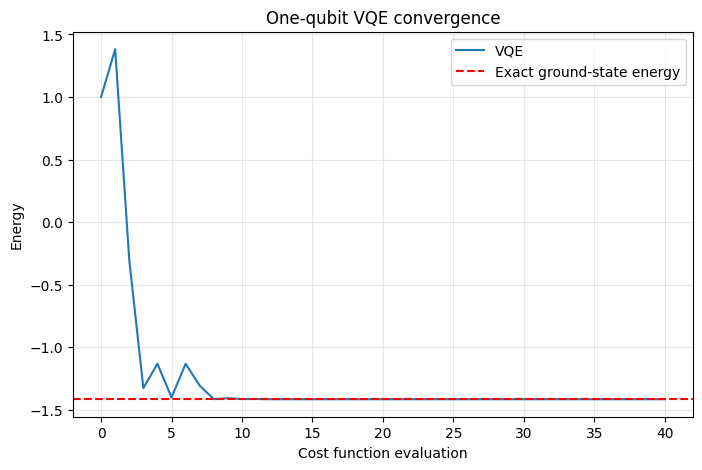

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(energy_history, label="VQE")
plt.axhline(
    -np.sqrt(2),
    linestyle="--",
    color="red",
    label="Exact ground-state energy"
)

plt.xlabel("Cost function evaluation")
plt.ylabel("Energy")
plt.title("One-qubit VQE convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()